<a href="https://colab.research.google.com/github/MenirahAlfadhel/-A-B-/blob/main/Copy_of%D9%85%D9%86%D9%8A%D8%B1%D9%87_%D8%A7%D9%84%D9%81%D8%A7%D8%B6%D9%84_%D8%A7%D9%84%D9%85%D8%B4%D8%B1%D9%88%D8%B9_%D8%A7%D9%84%D8%AE%D8%AA%D8%A7%D9%85%D9%8A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl">

# المشروع الختامي: تصميم تجربة وتحليلها

**برنامج التجارب واختبارات A/B والاستدلال السببي**، العرض يوم الأربعاء 11 نوفمبر 2026

</div>

<div dir="rtl">

## 0. بيانات المشروع

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| اسم المشروع | التوصيل المجاني للطلبات فوق 100 ريال |
| الاسم | منيره الفاضل |
| الجهة أو المنتج | تطبيق توصيل طلبات |
| المشكلة والهدف | رسوم التوصيل سبب رئيسي لترك السلة، والهدف تقرير إطلاق التوصيل المجاني فوق 100 ريال أو عدمه |

</div>

<div dir="rtl">

## 1. السؤال والفرضية

</div>

<div dir="rtl">

- **القرار:** هل نطلق التوصيل المجاني للطلبات فوق 100 ريال؟
- **الفرضية:** إذا قدمنا توصيلًا مجانيًا للطلبات فوق 100 ريال، فسترتفع نسبة الطلب، لأن رسوم التوصيل سبب رئيسي لترك السلة.
- **ما الذي يجعلنا نغير رأينا:**
  - لم ترتفع نسبة الطلب نقطة مئوية واحدة على الأقل.
  - أو انخفض الربح لكل مستخدم.
  - أو زاد الإلغاء أو التواصل مع الدعم.

</div>

<div dir="rtl">

## 2. التصميم

</div>

<div dir="rtl">

| البند | القيمة |
|---|---|
| المجتمع المستهدف | المستخدمون الجدد الذين يدخلون التطبيق خلال مدة التجربة |
| وحدة العشوأة | المستخدم: العرض يخصه وحده، ويبقى ثابتًا له طوال التجربة |
| نسبة التوزيع | 50% النسخة A (الوضع الحالي)، و50% النسخة B (توصيل مجاني فوق 100 ريال) |
| طريقة التوزيع | قرعة عشوائية لكل مستخدم عند دخوله |
| المدة | 7 أيام (تُحسب في القسم 3) |
| المقياس الرئيسي | نسبة المستخدمين الذين أكملوا طلبًا |
| مقاييس ثانوية | قيمة الطلب، والإيراد لكل مستخدم، ونسبة الطلبات 100 ريال فأكثر |
| مقاييس الحماية | الربح لكل مستخدم، ونسبة الإلغاء، ونسبة التواصل مع الدعم |
| شرط SUTVA | قرار المستخدم لا يتأثر بنسخة غيره. الخطر الوحيد: ضغط على المندوبين إذا زادت الطلبات كثيرًا، ونتوقعه صغيرًا |

</div>

<div dir="rtl">

## أدوات جاهزة

شغّل الخلية التالية بدون تعديل. فيها كل الدوال التي استخدمناها في الأيام الأربعة.

</div>

In [1]:
import warnings
warnings.filterwarnings("ignore")

import html
from IPython.display import HTML, display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib import ft2font
from scipy import stats

# الإصدارات الحديثة من matplotlib تعرض العربية مباشرة، والقديمة تحتاج مكتبتين صغيرتين
NATIVE_ARABIC = hasattr(ft2font, "__libraqm_version__")
if not NATIVE_ARABIC:
    try:
        import arabic_reshaper
        from bidi.algorithm import get_display
    except ImportError:
        import subprocess
        import sys
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "arabic-reshaper", "python-bidi"], check=True)
        import arabic_reshaper
        from bidi.algorithm import get_display

rng = np.random.default_rng(2026)

# ألوان البرنامج: A تركوازي، وB برتقالي، والقيمة الحقيقية كحلي، والطريقة الساذجة رمادي
TEAL, ORANGE, NAVY, GRAY = "#0E7490", "#E58A1F", "#0F2A3F", "#A9B4BC"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=[TEAL, ORANGE, NAVY, GRAY]),
    "axes.edgecolor": "#56656F", "axes.labelcolor": NAVY, "text.color": NAVY,
    "xtick.color": "#3D4F5C", "ytick.color": "#3D4F5C",
    "axes.grid": True, "grid.color": "#D8E1E7", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "font.size": 11,
    "legend.frameon": False,
})
pd.set_option("display.precision", 4)


def ar(text):
    """يجهز النص العربي ليظهر بالشكل والاتجاه الصحيحين داخل الرسوم."""
    text = str(text)
    return text if NATIVE_ARABIC else get_display(arabic_reshaper.reshape(text))


def say(*parts, sep=" "):
    """يطبع نصًا عربيًا من اليمين إلى اليسار."""
    text = html.escape(sep.join(str(p) for p in parts))
    display(HTML(f'<div dir="rtl" style="white-space: pre-wrap; line-height: 1.7;">{text}</div>'))

import statsmodels.formula.api as smf
from statsmodels.stats.multitest import multipletests
from IPython.display import Markdown, display


def n_per_group_proportions(p_control, p_treatment, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    var = p_control * (1 - p_control) + p_treatment * (1 - p_treatment)
    return int(np.ceil((z_a + z_b) ** 2 * var / (p_treatment - p_control) ** 2))


def mde_proportions(p_control, n_per_group, alpha=0.05, power=0.80):
    z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return (z_a + z_b) * np.sqrt(2 * p_control * (1 - p_control) / n_per_group)


def duration_days(n_per_group, daily_new_users, groups=2, round_to_weeks=True):
    days = int(np.ceil(n_per_group * groups / daily_new_users))
    return int(np.ceil(days / 7) * 7) if round_to_weeks else days


def srm_check(n_a, n_b, expected_share_b=0.5, threshold=0.001):
    total = n_a + n_b
    chi2, p = stats.chisquare([n_a, n_b], f_exp=[total * (1 - expected_share_b), total * expected_share_b])
    verdict = "خلل في التوزيع (SRM)، لا تثق بالنتائج" if p < threshold else "التوزيع سليم"
    say(f"A={n_a:,}   B={n_b:,}   χ²={chi2:.2f}   p={p:.2g}   النتيجة: {verdict}")
    return p


def diff_ci(a, b, alpha=0.05):
    """الفرق بين B وA مع فترة الثقة وقيمة p (بالتقريب الطبيعي)."""
    a, b = np.asarray(a, dtype=float), np.asarray(b, dtype=float)
    diff = b.mean() - a.mean()
    se = np.sqrt(a.var(ddof=1) / len(a) + b.var(ddof=1) / len(b))
    z = stats.norm.ppf(1 - alpha / 2)
    return {"الفرق": diff, "أدنى 95%": diff - z * se, "أعلى 95%": diff + z * se, "SE": se,
            "p": 2 * stats.norm.sf(abs(diff / se))}


def decide(ci_low, ci_high, mde, guardrails_ok=True):
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if ci_low > 0 and not guardrails_ok:
        return "لا نطلق الآن، لأن المقياس الرئيسي تحسن لكن أحد مقاييس الحماية ساء. نعالج المشكلة ثم نعيد التحقق."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


say("الأدوات جاهزة")

<div dir="rtl">

## 3. حجم العينة والمدة


</div>

In [2]:
CONFIG = {
    "project": "التوصيل المجاني للطلبات فوق 100 ريال",
    # ---- التصميم (تعرفه قبل التجربة) ----
    "baseline_conversion": 0.10,   # نسبة الطلب الحالية
    "mde_abs": 0.010,              # أصغر أثر مجدٍ تجاريًا: نقطة مئوية واحدة
    "alpha": 0.05,
    "power": 0.80,
    "daily_new_users": 5_000,      # عدد المستخدمين الجدد في اليوم
    "treatment_share": 0.5,
    # ---- المحاكاة ("الحقيقة" المخفية) ----
    "true_lift_abs": 0.012,        # التوصيل المجاني يرفع الطلب 1.2 نقطة
    "order_value_mean": 120,
    "order_value_sd": 50,
    "order_value_effect": 6,       # المستخدم يضيف منتجات ليصل إلى 100 ريال
    "margin": 0.25,
    "extra_cost_per_order_b": 6,   # متوسط تكلفة التوصيل التي تتحملها الشركة لكل طلب
    "cancel_rate": 0.05, "cancel_effect": 0.002,   # بعض من يزيدون السلة يلغون لاحقًا
    "support_rate": 0.03, "support_effect": 0.000,
    "activity_strength": 0.8,
    "novelty_boost": 0.3,          # حماس في أول أيام العرض ثم يهدأ
    "srm_bug_share": 0.0,
    "seed": 2026,
}

In [3]:
c = CONFIG
n_per_group = n_per_group_proportions(c["baseline_conversion"], c["baseline_conversion"] + c["mde_abs"], c["alpha"], c["power"])
days = duration_days(n_per_group, c["daily_new_users"])
say(f"المشروع: {c['project']}")
say(f"حجم العينة: {n_per_group:,} في كل مجموعة، أي {2 * n_per_group:,} مستخدم في المجموع")
say(f"المدة: {days} يومًا، وعدد الأسابيع الكاملة: {days // 7}")
n_planned = days * c["daily_new_users"] // 2
say(f"عدد المستخدمين المتوقع خلال المدة: {n_planned:,} في كل مجموعة")
for label, n_g in [("في المدة المخططة", n_planned), ("إذا اكتفينا بأسبوع واحد", 7 * c["daily_new_users"] // 2)]:
    m = mde_proportions(c["baseline_conversion"], n_g, c["alpha"], c["power"])
    say(f"{label}: أصغر أثر قابل للاكتشاف حوالي {m * 100:.2f} نقطة")


<div dir="rtl" align="right">



**1. هل المدة مقبولة؟**

نعم، المدة مقبولة مبدئيًا؛ إذ يمكن جمع العينة المطلوبة خلال أسبوع كامل، مما يراعي اختلاف سلوك المستخدمين بين أيام الأسبوع. كما يتيح حجم العينة اكتشاف أثر يقارب **0.90 نقطة مئوية** بقوة إحصائية **80%**، وهو أقل من الأثر المستهدف.

**2. لماذا اخترنا MDE بمقدار نقطة مئوية واحدة؟**

نظرًا للتكلفة الإضافية للتوصيل المجاني، نفترض أن التحسن الأقل من نقطة مئوية قد لا يكون مجديًا تجاريًا، وسيتم التحقق من ذلك من خلال تحليل الربحية.

**3. ماذا لو كانت المدة أطول من المقبول؟**

يمكن استخدام **CUPED** لتقليل التباين وحجم العينة المطلوب، أو إعادة تقييم تصميم التجربة، مع مراعاة الحد الأدنى للأثر المهم تجاريًا.

</div>


<div dir="rtl">

## 4. خطة التحليل


</div>

<div dir="rtl">

1. **فحص نسبة التوزيع (SRM):** اختبار كاي تربيع على أعداد A وB، وإذا كانت p أقل من 0.001 نوقف التحليل.
2. **المقياس الرئيسي:** نسبة المستخدمين الذين طلبوا، مع فترة ثقة 95%، ونعيد التقدير بطريقة CUPED باستخدام طلبات آخر 90 يومًا.
3. **مقاييس ثانوية:** قيمة الطلب، والإيراد لكل مستخدم، ونسبة الطلبات 100 ريال فأكثر، مع تصحيح Benjamini-Hochberg.
4. **مقاييس الحماية:** الربح لكل مستخدم، ونسبة الإلغاء، والتواصل مع الدعم. الحالة «تدهور دال» إذا كانت فترة الثقة كلها في الاتجاه السيئ، و«تحذير» إذا كان الاتجاه سيئًا وقيمة p أقل من 0.20.
5. **متى نحلل:** مرة واحدة بعد اكتمال 7 أيام، بدون اطلاع مبكر.
6. **قاعدة القرار:** نطلق فقط إذا كان الأثر إيجابيًا بثقة، ولا يقل عن نقطة مئوية واحدة، ولا يوجد تدهور أو تحذير في مقاييس الحماية.

</div>

<div dir="rtl">

## 5. إنشاء البيانات بالمحاكاة

تنشئ المحاكاة كل المستخدمين الذين يدخلون التجربة خلال المدة، وكل مستخدم في صف واحد. لكل مستخدم: النسخة، ويوم الدخول، وطلباته في آخر 90 يومًا قبل التجربة، وهل طلب، وقيمة الطلب، والربح، والإلغاء، والتواصل مع الدعم.

</div>

In [4]:
def simulate_experiment(cfg, duration_days):
    """كل المستخدمين الذين يدخلون خلال مدة التجربة (المدة مضروبة في عدد المستخدمين اليومي)."""
    r = np.random.default_rng(cfg["seed"])
    n = duration_days * cfg["daily_new_users"]
    is_b = (r.random(n) < cfg["treatment_share"]).astype(int)
    day = r.integers(1, duration_days + 1, n)
    activity = r.normal(0, 1, n)                                             # نشاط المستخدم (لا نقيسه مباشرة)
    base = cfg["baseline_conversion"]
    logit = np.log(base / (1 - base)) + cfg["activity_strength"] * activity
    p0 = 1 / (1 + np.exp(-logit))
    p0 = np.clip(p0 * base / p0.mean(), 0, 1)                                # نضبط المتوسط ليساوي خط الأساس
    pre_orders_90d = r.poisson(5 * p0 / base)                                # الطلبات في آخر 90 يومًا
    lift = cfg["true_lift_abs"] * (1 + cfg["novelty_boost"] * np.exp(-(day - 1) / 3))
    ordered = r.binomial(1, np.clip(p0 + lift * is_b, 0, 1))
    value = np.maximum(10, r.normal(cfg["order_value_mean"] + cfg["order_value_effect"] * is_b, cfg["order_value_sd"]))
    order_value = np.where(ordered == 1, value, np.nan)
    revenue = ordered * value
    profit = ordered * (cfg["margin"] * value - cfg["extra_cost_per_order_b"] * is_b)
    cancelled = np.where(ordered == 1, r.binomial(1, np.clip(cfg["cancel_rate"] + cfg["cancel_effect"] * is_b, 0, 1)), np.nan)
    support = r.binomial(1, np.clip(cfg["support_rate"] + cfg["support_effect"] * is_b, 0, 1))
    df = pd.DataFrame({"variant": np.where(is_b == 1, "B", "A"), "day": day, "pre_orders_90d": pre_orders_90d,
                       "ordered": ordered, "order_value": order_value, "revenue": revenue, "profit": profit,
                       "cancelled": cancelled, "contacted_support": support})
    if cfg["srm_bug_share"] > 0:                                              # خلل: سجلات ضائعة من B لقليلي النشاط
        lost = (df["variant"] == "B") & (activity < 0) & (r.random(n) < cfg["srm_bug_share"] * 2)
        df = df[~lost]
    return df.reset_index(drop=True)


data = simulate_experiment(CONFIG, days)
say(f"عدد المستخدمين: {len(data):,}")
data.head()

,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,B,1,2,0,NaN,0.0,0.0,NaN,0
1,A,3,2,0,NaN,0.0,0.0,NaN,0
2,B,5,7,0,NaN,0.0,0.0,NaN,0
3,B,5,8,0,NaN,0.0,0.0,NaN,0
4,B,2,4,0,NaN,0.0,0.0,NaN,0


In [5]:
data = simulate_experiment(CONFIG, days)
data.insert(0, "user_id", range(1, len(data) + 1))
say(f"اكتمال البيانات: {len(data):,} سجل من {days * CONFIG['daily_new_users']:,} متوقع")
say(f"السجلات المكررة: {data['user_id'].duplicated().sum()}")
say(f"القيم المفقودة في قيمة الطلب والإلغاء تخص من لم يطلب فقط: {(data['ordered'] == 0).sum():,} مستخدم")
say(f"عدد المستخدمين: {len(data):,}")
data.head()

,user_id,variant,day,pre_orders_90d,ordered,order_value,revenue,profit,cancelled,contacted_support
0,1,B,1,2,0,NaN,0.0,0.0,NaN,0
1,2,A,3,2,0,NaN,0.0,0.0,NaN,0
2,3,B,5,7,0,NaN,0.0,0.0,NaN,0
3,4,B,5,8,0,NaN,0.0,0.0,NaN,0
4,5,B,2,4,0,NaN,0.0,0.0,NaN,0


<div dir="rtl">

## 6. فحوص الثقة

</div>

In [6]:
counts = data["variant"].value_counts()
srm_check(counts.get("A", 0), counts.get("B", 0), CONFIG["treatment_share"]);

<div dir="rtl">

التوزيع سليم: الفرق بين المجموعتين 190 مستخدمًا فقط من 35,000، وقيمة p تساوي 0.31، وهي أكبر بكثير من 0.001، فلا يوجد خلل في التوزيع ونكمل التحليل.

</div>


<div dir="rtl">

## 7. التحليل

### 7.1 المقياس الرئيسي، مع CUPED

</div>

In [7]:
A, B = data[data.variant == "A"], data[data.variant == "B"]
primary = diff_ci(A["ordered"], B["ordered"])

theta = np.cov(data["ordered"], data["pre_orders_90d"])[0, 1] / data["pre_orders_90d"].var(ddof=1)
adjusted = data["ordered"] - theta * (data["pre_orders_90d"] - data["pre_orders_90d"].mean())
primary_cuped = diff_ci(adjusted[data.variant == "A"], adjusted[data.variant == "B"])

out = pd.DataFrame([primary, primary_cuped], index=["بدون تعديل", "مع CUPED"])
out[["الفرق", "أدنى 95%", "أعلى 95%"]] *= 100
say(f"نسبة الطلب في A: {A['ordered'].mean():.2%}، وفي B: {B['ordered'].mean():.2%}")
say(f"انخفاض التباين بطريقة CUPED: {1 - (primary_cuped['SE'] / primary['SE']) ** 2:.0%}")

# إضافة: الأثر النسبي، ومقارنة التقدير بالأثر الحقيقي في المحاكاة
rel_lift = primary["الفرق"] / A["ordered"].mean()
true_avg_lift = CONFIG["true_lift_abs"] * (1 + CONFIG["novelty_boost"] * np.exp(-(data["day"] - 1) / 3)).mean()
say(f"الأثر النسبي: {rel_lift:.1%}")
say(f"الأثر الحقيقي في المحاكاة: {true_avg_lift * 100:.2f} نقطة، وهو داخل فترة الثقة: {primary['أدنى 95%'] <= true_avg_lift <= primary['أعلى 95%']}")
out.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p
بدون تعديل,1.056,0.411,1.702,0.003,0.001
مع CUPED,1.075,0.442,1.708,0.003,0.001


<div dir="rtl">

ارتفعت نسبة الطلب من 10.09% إلى 11.15%، أي 1.06 نقطة مئوية (زيادة نسبية 10.5%)، وفترة الثقة كلها فوق الصفر (من 0.41 إلى 1.70)، فالأثر إيجابي بثقة. وخفّضت CUPED التباين 4% فقط، لأن المقياس نعم أو لا، وطريقة CUPED تكون أقوى في المقاييس المتصلة مثل الإيراد. والأثر الحقيقي في المحاكاة (1.36 نقطة) يقع داخل فترة الثقة، فالتحليل وصل للحقيقة.

</div>

<div dir="rtl">

### 7.2 المقاييس الثانوية، مع تصحيح الاختبارات المتعددة

</div>

In [8]:
A_orders, B_orders = A[A.ordered == 1], B[B.ordered == 1]
secondary = {
    "قيمة الطلب (لمن طلب)": diff_ci(A_orders["order_value"], B_orders["order_value"]),
    "الإيراد لكل مستخدم": diff_ci(A["revenue"], B["revenue"]),
    "نسبة الطلبات 100 ريال فأكثر": diff_ci(A_orders["order_value"] >= 100, B_orders["order_value"] >= 100),
}
sec = pd.DataFrame(secondary).T
sec["دال بعد تصحيح BH"] = multipletests(sec["p"].astype(float), alpha=0.05, method="fdr_bh")[0]
sec.round(3)

,الفرق,أدنى 95%,أعلى 95%,SE,p,دال بعد تصحيح BH
قيمة الطلب (لمن طلب),6.993,3.800,10.186,1.629,0.000,True
الإيراد لكل مستخدم,2.031,1.173,2.890,0.438,0.000,True
نسبة الطلبات 100 ريال فأكثر,0.048,0.018,0.078,0.015,0.002,True


<div dir="rtl">

ارتفعت قيمة الطلب 7 ريالات تقريبًا، والإيراد لكل مستخدم ريالين، وزادت نسبة الطلبات التي تتجاوز 100 ريال 4.8 نقطة، أي أن المستخدمين يضيفون منتجات للوصول إلى حد التوصيل المجاني. واستخدمنا تصحيح BH لأننا نختبر ثلاثة مقاييس معًا، وبقيت كلها دالة بعده.

</div>

<div dir="rtl">

### 7.3 مقاييس الحماية

</div>

In [9]:
guardrail_defs = {                       # العمود: (الاسم، والاتجاه السيئ)
    "profit": ("الربح لكل مستخدم", "down"),
    "cancelled": ("نسبة إلغاء الطلبات", "up"),
    "contacted_support": ("التواصل مع الدعم", "up"),
}
rows, guard_status = [], {}
for col, (label, bad) in guardrail_defs.items():
    res = diff_ci(A[col].dropna(), B[col].dropna())
    if bad == "down":
        harmful, worse = res["أعلى 95%"] < 0, res["الفرق"] < 0
    else:
        harmful, worse = res["أدنى 95%"] > 0, res["الفرق"] > 0
    status = "تدهور دال" if harmful else ("تحذير" if (worse and res["p"] < 0.20) else "سليم")
    guard_status[label] = status
    rows.append({"المقياس": label, "A": A[col].mean(), "B": B[col].mean(), **res, "الحالة": status})
guard_table = pd.DataFrame(rows).set_index("المقياس")
guard_table.round(4)

,A,B,الفرق,أدنى 95%,أعلى 95%,SE,p,الحالة
المقياس,,,,,,,,
الربح لكل مستخدم,2.9909,2.8297,-0.1612,-0.3579,0.0355,0.1004,0.1082,تحذير
نسبة إلغاء الطلبات,0.0415,0.0423,0.0008,-0.0121,0.0137,0.0066,0.9086,سليم
التواصل مع الدعم,0.0313,0.0307,-0.0005,-0.0041,0.0031,0.0019,0.7840,سليم


<div dir="rtl">

انخفض الربح لكل مستخدم من 2.99 إلى 2.83 ريال (0.16 ريال، أي 5%). وهذا الانخفاض غير دال إحصائيًا، لكن عدم الدلالة لا يعني عدم وجود ضرر، فالتجربة صُممت لقياس نسبة الطلب لا الربح. لذلك صنّفناه «تحذير». أما الإلغاء والتواصل مع الدعم فلم يتغيرا.

</div>

<div dir="rtl">

### 7.4 فحص أثر الحداثة

</div>

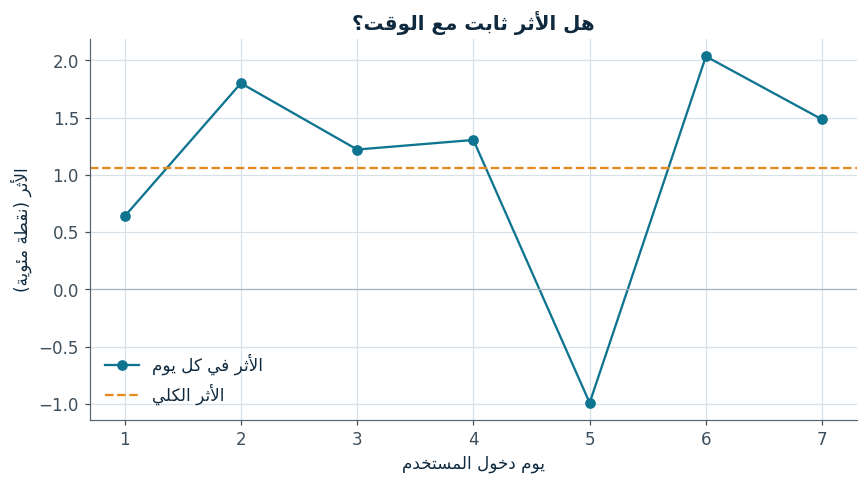

In [10]:
daily = data.groupby(["day", "variant"])["ordered"].mean().unstack()
daily_lift = (daily["B"] - daily["A"]) * 100
plt.plot(daily_lift.index, daily_lift.values, marker="o", color=TEAL, label=ar("الأثر في كل يوم"))
plt.axhline(primary["الفرق"] * 100, color=ORANGE, linestyle="--", label=ar("الأثر الكلي"))
plt.axhline(0, color=GRAY, linewidth=0.8)
plt.xlabel(ar("يوم دخول المستخدم"))
plt.ylabel(ar("الأثر (نقطة مئوية)"))
plt.title(ar("هل الأثر ثابت مع الوقت؟"))
plt.legend()
plt.show()

<div dir="rtl">

يتذبذب الأثر اليومي حول الأثر الكلي (بين −1 و+2 نقطة تقريبًا) بدون انخفاض واضح مع الوقت، فلا يظهر أثر حداثة قوي. لكن عدد المستخدمين في كل يوم قليل، فالحكم على استمرار الأثر يحتاج تجربة أطول.

</div>

<div dir="rtl">

## 8. التقرير والتوصية


</div>

In [11]:
annual_users = CONFIG["daily_new_users"] * 365      # من بيانات المشروع بدل رقم ثابت


def decide_v2(diff, ci_low, ci_high, mde, guard_status):
    """قاعدة قرار تأخذ في الاعتبار الحد المجدي تجاريًا وحالة التحذير."""
    statuses = list(guard_status.values())
    if ci_high < 0:
        return "لا نطلق، لأن النسخة الجديدة أضرت بالمقياس الرئيسي."
    if "تدهور دال" in statuses:
        return "لا نطلق الآن، لأن أحد مقاييس الحماية ساء بشكل دال."
    if ci_low > 0 and diff < mde:
        return "الأثر إيجابي لكنه أصغر من الحد المجدي تجاريًا، فلا نطلق بصيغته الحالية."
    if ci_low > 0 and "تحذير" in statuses:
        return "الأثر على الطلب إيجابي، لكن أحد مقاييس الحماية يتجه سلبًا. لا نطلق للجميع قبل تجربة تركز على الربحية."
    if ci_low > 0:
        return "نطلق، لأن الأثر إيجابي بثقة ومقاييس الحماية سليمة."
    if ci_high < mde:
        return "لا نطلق، لأننا استبعدنا وجود أثر بالحجم الذي يهمنا."
    return "لا نقرر بعد. نمدد التجربة، أو نعيد تصميمها بقوة أعلى."


decision = decide_v2(primary["الفرق"], primary["أدنى 95%"], primary["أعلى 95%"], CONFIG["mde_abs"], guard_status)
profit = guard_table.loc["الربح لكل مستخدم"]
guard_rows = "\n".join(f"| {k} | {v} |" for k, v in guard_status.items())

report = f"""
<div dir="rtl">

### تقرير التجربة: {CONFIG['project']}

**القرار:** {decision}

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من {A['ordered'].mean():.2%} إلى {B['ordered'].mean():.2%} |
| الأثر | {primary['الفرق'] * 100:.2f} نقطة (فترة الثقة 95%: من {primary['أدنى 95%'] * 100:.2f} إلى {primary['أعلى 95%'] * 100:.2f}) |
| الأثر مع CUPED | {primary_cuped['الفرق'] * 100:.2f} نقطة (من {primary_cuped['أدنى 95%'] * 100:.2f} إلى {primary_cuped['أعلى 95%'] * 100:.2f}) |
| التغير في قيمة الطلب | {sec.loc['قيمة الطلب (لمن طلب)', 'الفرق']:.2f} ريال |
| التغير التقديري في الربح السنوي | {profit['الفرق'] * annual_users / 1e6:.2f} مليون ريال (من {profit['أدنى 95%'] * annual_users / 1e6:.2f} إلى {profit['أعلى 95%'] * annual_users / 1e6:.2f}) |

| مقياس الحماية | الحالة |
|---|---|
{guard_rows}

</div>
"""
display(Markdown(report))


<div dir="rtl">

### تقرير التجربة: التوصيل المجاني للطلبات فوق 100 ريال

**القرار:** الأثر على الطلب إيجابي، لكن أحد مقاييس الحماية يتجه سلبًا. لا نطلق للجميع قبل تجربة تركز على الربحية.

| البند | القيمة |
|---|---|
| المقياس الرئيسي | نسبة الطلب من 10.09% إلى 11.15% |
| الأثر | 1.06 نقطة (فترة الثقة 95%: من 0.41 إلى 1.70) |
| الأثر مع CUPED | 1.07 نقطة (من 0.44 إلى 1.71) |
| التغير في قيمة الطلب | 6.99 ريال |
| التغير التقديري في الربح السنوي | -0.29 مليون ريال (من -0.65 إلى 0.06) |

| مقياس الحماية | الحالة |
|---|---|
| الربح لكل مستخدم | تحذير |
| نسبة إلغاء الطلبات | سليم |
| التواصل مع الدعم | سليم |

</div>


<div dir="rtl">

- **التوصية:** لا نطلق التوصيل المجاني فوق 100 ريال لجميع المستخدمين الآن. رفع العرض نسبة الطلب 1.06 نقطة وقيمة الطلب 7 ريالات، لكن الربحية غير مؤكدة: الربح لكل مستخدم يتجه إلى الانخفاض (التقدير −5%، والتغير السنوي التقديري −0.29 مليون ريال، من −0.65 إلى +0.06)، فلا نستطيع استبعاد خسارة مهمة.
- **الخطوة التالية:** تجربة جديدة تقارن حدًا أعلى للتوصيل المجاني (مثل 150 ريالًا) أو دعمًا جزئيًا لرسوم التوصيل، ويكون الربح فيها المقياس الرئيسي مع عينة كافية لقياسه.
- **القيود:** البيانات من محاكاة، والمحاكاة تطبق تكلفة التوصيل على كل طلبات B كمتوسط، ومدة أسبوع لا تكشف السلوك بعيد المدى، والتجربة لم تُصمم بقوة كافية لقياس الربح.

</div>